# Projeto Integrador P15 UNIFAP
## Demanda diária de bicicletas e condições meteorológicas
**Autor:** Márcio Alberto Monteiro de Brito  
**Curso:** Especialização em Projetos em Inteligência Artificial — UNIFAP Digital  
**Ano:** 2026

Objetivo: integrar duas fontes independentes, documentar ETL e PostgreSQL e comparar três modelos de regressão para explicar a demanda diária no Capital Bikeshare em Washington DC. O estudo usa clima observado do dia; os resultados são retrospectivos e condicionais a esse clima, não uma avaliação de previsão antecipada.

Fontes: [UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), DOI 10.24432/C5W894, Hadi Fanaee-T (2013); [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), ERA5, CC BY 4.0. Weather data by Open-Meteo.com. Acesso em 9 out. 2026. As fontes foram integradas e transformadas; atribuição não implica endosso.


In [1]:
from pathlib import Path
import os, sys, json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
if not (ROOT / 'src/pipeline.py').exists(): raise RuntimeError('Execute dentro da pasta do projeto ou notebooks')
sys.path.insert(0, str(ROOT / 'src'))
from pipeline import extract, integrate, train, NUM, CAT


## 1 Coleta e qualidade das fontes
Contagens e calendário vêm da UCI. Temperatura média (°C), precipitação diária (mm) e vento máximo a 10 m (km/h) vêm de ERA5 pela API Open-Meteo, com fuso America/New_York, coordenadas 38,9072 e −77,0369 e período 2011–2012. O ponto do clima aproxima a área atendida pelo sistema. A presença de dois arquivos de um mesmo dataset não foi tratada como duas fontes independentes.

Os arquivos originais são mantidos para reprodução, com hashes SHA256. Datas devem ser únicas em cada fonte; campos obrigatórios não podem ter valores ausentes. Quantidades e precipitação devem ser não negativas.


In [2]:
bikes, weather = extract()
display(bikes.head(), weather.head())
print('Linhas por fonte:', len(bikes), len(weather))
print('Ausentes:', bikes.isna().sum().sum(), weather.isna().sum().sum())
print(json.dumps(json.loads((ROOT/'data/raw/manifest.json').read_text()), indent=2))


,dteday,holiday,workingday,cnt
0,2011-01-01,0,0,985
1,2011-01-02,0,0,801
2,2011-01-03,0,1,1349
3,2011-01-04,0,1,1562
4,2011-01-05,0,1,1600


,dteday,temperature_2m_mean,precipitation_sum,wind_speed_10m_max
0,2011-01-01,8.6,2.5,17.7
1,2011-01-02,9.6,3.0,18.9
2,2011-01-03,-0.2,0.0,17.4
3,2011-01-04,0.2,0.0,11.2
4,2011-01-05,0.4,0.0,13.9


Linhas por fonte: 731 731
Ausentes: 0 0
{
  "sources": [
    {
      "name": "UCI Bike Sharing",
      "url": "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
    },
    {
      "name": "Open-Meteo ERA5",
      "url": "https://archive-api.open-meteo.com/v1/archive",
      "params": {
        "latitude": 38.9072,
        "longitude": -77.0369,
        "start_date": "2011-01-01",
        "end_date": "2012-12-31",
        "daily": "temperature_2m_mean,precipitation_sum,wind_speed_10m_max",
        "timezone": "America/New_York",
        "models": "era5"
      }
    }
  ],
  "sha256": {
    "uci.zip": "b70182d0d0508e9abbb79306ce5c0cec34869000f8220175ac83d11dbe845401",
    "weather.json": "f78c924016d9d0d24e404c316e812df75cffeb24b6ddb8e7a0e6a0cb64059aae"
  }
}


## 2 Armazenamento e integração
O arquivo `sql/schema.sql` define duas tabelas com chave primária por data e restrições de integridade e uma view integrada. O ETL carrega as tabelas em uma transação e lê a junção SQL. Use `DATABASE_URL` para executar com PostgreSQL. A alternativa sem banco serve para verificar os demais componentes e não atende, sozinha, à entrega P15.


In [3]:
offline = not bool(os.environ.get('DATABASE_URL'))
if offline: print('VERIFICAÇÃO SEM BANCO: para a entrega P15, execute com DATABASE_URL configurada.')
data = integrate(bikes, weather, offline=offline)
print('Integração PostgreSQL:', not offline)
display(data.head())
assert len(data) == 731
assert data.dteday.is_unique
assert not data.isna().any().any()


,dteday,holiday,workingday,cnt,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,weekday,trend,month_sin,month_cos
0,2011-01-01,0,0,985,8.6,2.5,17.7,5,0,0.5,0.866025
1,2011-01-02,0,0,801,9.6,3.0,18.9,6,1,0.5,0.866025
2,2011-01-03,0,1,1349,-0.2,0.0,17.4,0,2,0.5,0.866025
3,2011-01-04,0,1,1562,0.2,0.0,11.2,1,3,0.5,0.866025
4,2011-01-05,0,1,1600,0.4,0.0,13.9,2,4,0.5,0.866025


VERIFICAÇÃO SEM BANCO: para a entrega P15, execute com DATABASE_URL configurada.
Integração PostgreSQL: False


## 3 Análise exploratória
Verificamos distribuição do alvo, sazonalidade mensal, correlações meteorológicas e dias extremos. Correlação não demonstra causalidade: crescimento do serviço, calendário e clima podem variar juntos. Os dados de 2011 e 2012 não representam automaticamente o comportamento atual.


In [4]:
display(data.describe())
display(data.groupby(pd.to_datetime(data.dteday).dt.month)['cnt'].agg(['count','mean','min','max']))
display(data[NUM + ['cnt']].corr()[['cnt']])
display(data.nsmallest(5, 'cnt')[['dteday','cnt','precipitation_sum','wind_speed_10m_max']])


,holiday,workingday,cnt,temperature_2m_mean,precipitation_sum,wind_speed_10m_max,weekday,trend,month_sin,month_cos
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,7.310000e+02,7.310000e+02
mean,0.028728,0.683995,4504.348837,15.119015,2.902052,15.274966,3.002736,365.000000,-4.189026e-03,-1.685432e-03
std,0.167155,0.465233,1937.211452,9.292363,7.368912,5.718661,2.004787,211.165812,7.063675e-01,7.087979e-01
min,0.000000,0.000000,22.000000,-5.700000,0.000000,6.400000,0.000000,0.000000,-1.000000e+00,-1.000000e+00
25%,0.000000,0.000000,3152.000000,7.000000,0.000000,11.200000,1.000000,182.500000,-8.660254e-01,-8.660254e-01
50%,0.000000,1.000000,4548.000000,15.300000,0.000000,13.900000,3.000000,365.000000,-2.449294e-16,-1.836970e-16
75%,0.000000,1.000000,5956.000000,23.350000,2.100000,18.300000,5.000000,547.500000,5.000000e-01,8.660254e-01
max,1.000000,1.000000,8714.000000,33.600000,83.600000,43.200000,6.000000,730.000000,1.000000e+00,1.000000e+00


,count,mean,min,max
dteday,,,,
1,62,2176.338710,431,4521
2,57,2655.298246,1005,5062
3,62,3692.258065,605,8362
4,60,4484.900000,795,7460
5,62,5349.774194,2633,8294
6,60,5772.366667,3767,8120
7,62,5563.677419,3285,8173
8,62,5664.419355,1115,7865
9,60,5766.516667,1842,8714


,cnt
temperature_2m_mean,0.606249
precipitation_sum,-0.278709
wind_speed_10m_max,-0.375405
trend,0.628830
month_sin,-0.389470
month_cos,-0.450424
cnt,1.000000


,dteday,cnt,precipitation_sum,wind_speed_10m_max
667,2012-10-29,22,83.6,43.2
26,2011-01-27,431,0.6,21.3
725,2012-12-26,441,22.9,28.7
25,2011-01-26,506,24.7,23.7
64,2011-03-06,605,39.5,26.0


## 4 Engenharia de features e prevenção de vazamento
Features: temperatura, precipitação, vento, tendência em dias desde 01/01/2011, mês representado por seno e cosseno, dia da semana, feriado e dia útil. O dia da semana é calculado pela data. A tendência representa crescimento temporal do serviço, mas modelos de árvores têm dificuldade de extrapolar fora da faixa do treino.

`casual` e `registered` são excluídos porque sua soma é `cnt`. A data identifica a integração e a divisão temporal, sem entrar diretamente no estimador. Imputação por mediana, padronização e codificação one-hot são ajustadas exclusivamente no treino de cada fold pelo Pipeline do scikit-learn. As fontes atuais são completas; o imputador permite inferência futura com campos numéricos ausentes, que deve ser monitorada.


In [5]:
print('Features numéricas:', NUM)
print('Features categóricas:', CAT)
cut = int(len(data) * 0.8)
print('Treino:', data.dteday.iloc[0], 'até', data.dteday.iloc[cut-1], 'n =', cut)
print('Teste:', data.dteday.iloc[cut], 'até', data.dteday.iloc[-1], 'n =', len(data)-cut)


Features numéricas: ['temperature_2m_mean', 'precipitation_sum', 'wind_speed_10m_max', 'trend', 'month_sin', 'month_cos']
Features categóricas: ['weekday', 'holiday', 'workingday']
Treino: 2011-01-01 até 2012-08-06 n = 584
Teste: 2012-08-07 até 2012-12-31 n = 147


## 5 Treinamento e avaliação
Ridge, Random Forest e Gradient Boosting são comparados com hiperparâmetros fixos. Quatro folds de TimeSeriesSplit no treino produzem RMSE de validação. O menor RMSE médio de validação escolhe o modelo antes de consultar o teste final. Uma referência que prevê a média do treino permite verificar se o modelo acrescenta capacidade preditiva. O teste é o último bloco de 20% das datas; não há embaralhamento.

MAE e RMSE têm unidade de aluguéis por dia. RMSE penaliza mais os grandes erros. R² compara o erro com a variação do alvo no teste. O arquivo `.pkl` contém o pré-processamento e o modelo treinados no bloco de treino; não há retreino com o teste.


In [6]:
summary = train(data, offline=offline)
metrics = pd.read_csv(ROOT/'results/metrics.csv')
display(metrics)
print('Modelo escolhido na validação:', summary['selected_model'])


,model,cv_rmse_mean,cv_rmse_std,mae,rmse,r2
0,Ridge,993.022047,66.728601,1001.167559,1341.189205,0.488137
1,RandomForest,930.451646,323.740592,815.225421,1197.915971,0.591656
2,GradientBoosting,914.057268,325.104359,800.515198,1123.587239,0.640758
3,BaselineMean,NaN,NaN,2290.412706,2560.555848,-0.865701


{
  "selected_model": "GradientBoosting",
  "selection": "menor RMSE de validação temporal no treino",
  "rows": 731,
  "train_rows": 584,
  "test_rows": 147,
  "train_start": "2011-01-01",
  "train_end": "2012-08-06",
  "test_start": "2012-08-07",
  "test_end": "2012-12-31",
  "postgresql_executed": false,
  "features": [
    "temperature_2m_mean",
    "precipitation_sum",
    "wind_speed_10m_max",
    "trend",
    "month_sin",
    "month_cos",
    "weekday",
    "holiday",
    "workingday"
  ],
  "limitations": [
    "Clima observado do próprio dia: análise retrospectiva condicional, não previsão antecipada operacional.",
    "Reanálise ERA5 em um ponto representa aproximadamente a área de Washington DC.",
    "Apenas dois anos e uma cidade; não generalizar a Macapá sem validação local.",
    "casual e registered excluídos pois somam a variável alvo cnt."
  ]
}
           model  cv_rmse_mean  cv_rmse_std         mae        rmse        r2
           Ridge    993.022047    66.728601 10

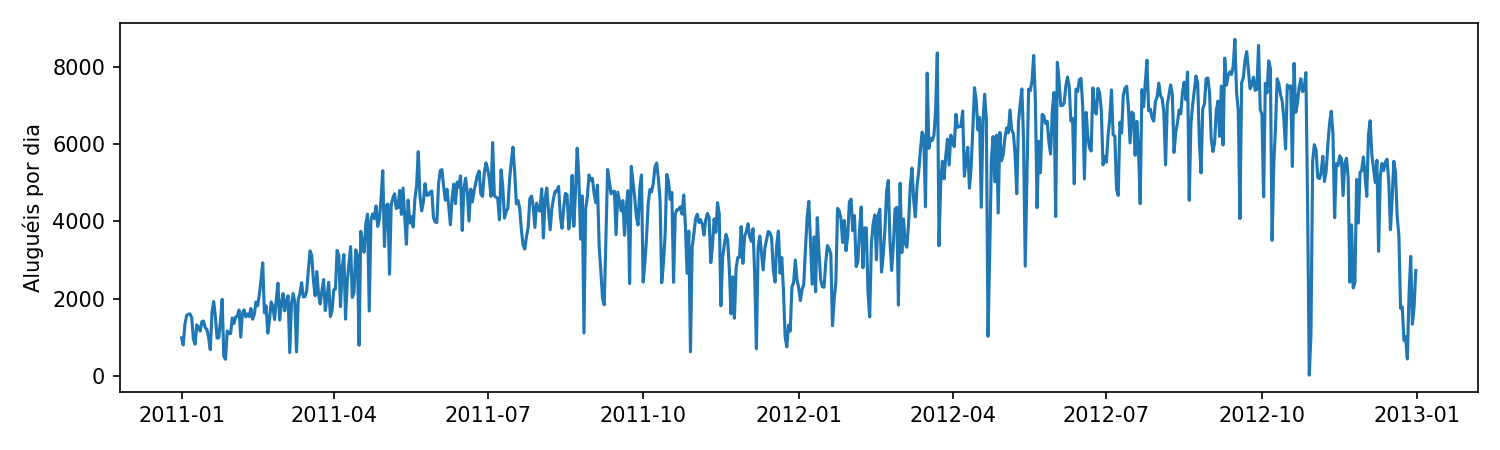

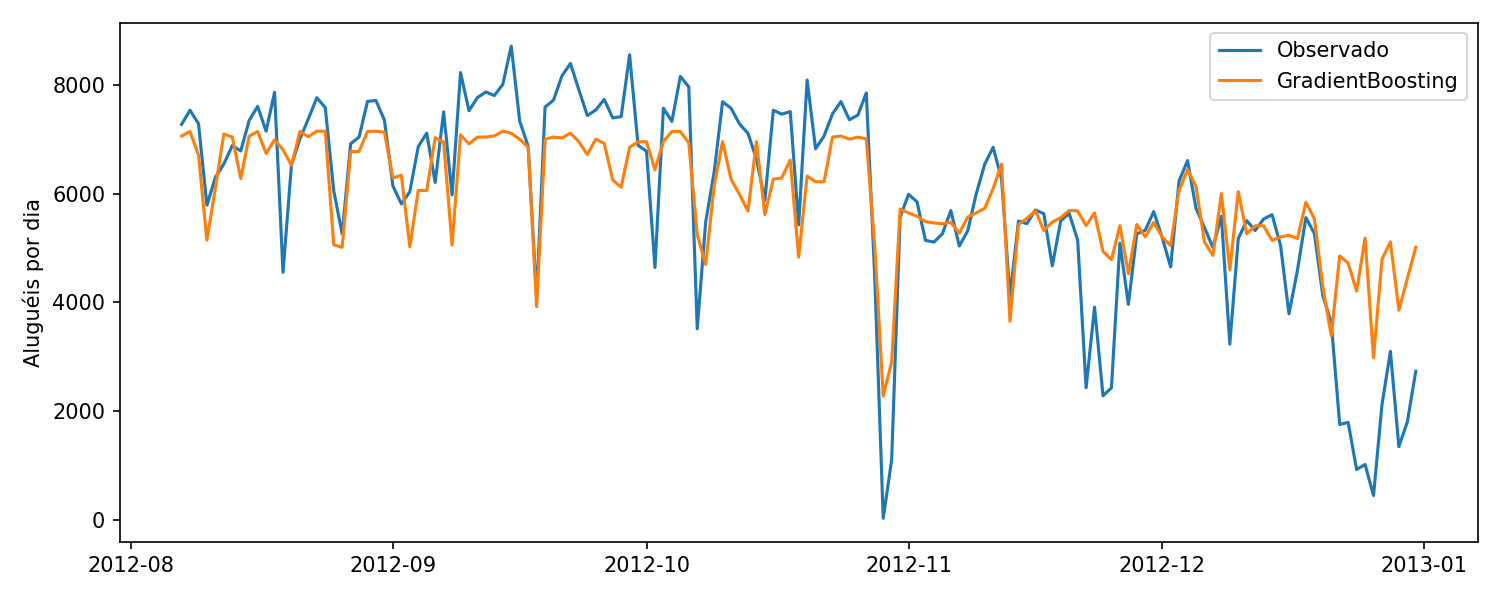

,date,actual,prediction,residual,abs_error
140,2012-12-25,1013,5179.559015,-4166.559015,4166.559015
139,2012-12-24,920,4204.832088,-3284.832088,3284.832088
137,2012-12-22,1749,4852.277236,-3103.277236,3103.277236
107,2012-11-22,2425,5409.426663,-2984.426663,2984.426663
138,2012-12-23,1787,4718.450839,-2931.450839,2931.450839


In [7]:
display(Image(filename=str(ROOT/'results/demand.png')))
display(Image(filename=str(ROOT/'results/predictions.png')))
predictions = pd.read_csv(ROOT/'results/predictions.csv')
display(predictions.assign(abs_error=predictions.residual.abs()).nlargest(5,'abs_error'))


## 6 Inferência e verificação do artefato
O modelo salvo pode ser carregado e aplicado a uma tabela com as mesmas nove features. O exemplo abaixo reproduz a previsão do primeiro dia do teste. Carregue apenas arquivos pickle de origem confiável.


In [8]:
import joblib, numpy as np
model = joblib.load(ROOT/'models/best_model.pkl')
example = data.iloc[[cut]][NUM + CAT]
y = float(model.predict(example)[0])
assert np.isclose(y, predictions.prediction.iloc[0])
print('Previsão reproduzida:', round(y,2))


Previsão reproduzida: 7057.55


## 7 Conclusões e limitações
O modelo selecionado deve ser interpretado pelos resultados calculados abaixo. O desempenho em uma cidade e dois anos não assegura generalização. Clima de reanálise não é uma previsão disponível antes do dia de aluguel; para uso operacional, é necessário repetir o experimento com previsões históricas disponíveis no momento da decisão. Dias extremos e mudanças na rede de bicicletas podem produzir erros grandes. O projeto não mede causalidade do clima nem foi validado em Macapá.


In [9]:
best = metrics.loc[metrics.model == summary['selected_model']].iloc[0]
base = metrics.loc[metrics.model == 'BaselineMean'].iloc[0]
print(f"{summary['selected_model']}: MAE={best.mae:.2f}, RMSE={best.rmse:.2f}, R²={best.r2:.3f}")
print(f"Redução de RMSE sobre a média do treino: {100*(1-best.rmse/base.rmse):.1f}%")
print('PostgreSQL executado nesta sessão:', summary['postgresql_executed'])


GradientBoosting: MAE=800.52, RMSE=1123.59, R²=0.641
Redução de RMSE sobre a média do treino: 56.1%
PostgreSQL executado nesta sessão: False


## 8 Checklist de entrega
- Duas fontes independentes coletadas e identificadas.
- PostgreSQL: confirmar execução real e o campo `postgresql_executed` no resumo.
- ETL, features, três modelos, métricas e modelo salvo incluídos.
- Notebook documentado e README com comandos de reprodução incluídos.
- Publicar os arquivos em repositório Git acessível ao professor.
- Enviar o link no Moodle e anexar este notebook `.ipynb`.

O envio ao Moodle e a publicação remota do Git precisam ser realizados após a revisão da equipe. Inclua os nomes dos demais integrantes, se houver, na identificação.
